# Imports

In [1]:
import warnings
warnings.filterwarnings("ignore")

import sys
import os
parent_dir = os.path.abspath("../../libraries/surrogate_modelling")
sys.path.insert(0, parent_dir)

from preprocess_modeshape_data import *
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates
from mpl_toolkits.mplot3d import Axes3D
import plotly.graph_objects as go
import plotly.express as px
from plotly.colors import sample_colorscale
from matplotlib.cm import ScalarMappable
from plotly.subplots import make_subplots

/home/vemese/miniforge3/envs/Buildchain_sandbox/lib/python3.10/site-packages/shap/plots/colors/_colorconv.py:819: DeprecationWarning: Converting `np.inexact` or `np.floating` to a dtype is deprecated. The current result is `float64` which is not strictly correct.
  if np.issubdtype(dtype_in, np.dtype(dtype).type):
<frozen importlib._bootstrap>:241: RuntimeWarning: numpy.ufunc size changed, may indicate binary incompatibility. Expected 216 from C header, got 232 from PyObject


# Functions

In [2]:
def scatter_plot_modes_subplots(modeshapes_dict, x_key='Humidity', y_key='frequency', modes=[0, 1, 2, 3, 6]):
    num_plots = len(modes)
    rows = (num_plots + 1) // 2  # arrange in 2 columns
    cols = 2 if num_plots > 1 else 1

    fig = make_subplots(rows=rows, cols=cols, subplot_titles=[f"Mode {m}" for m in modes])

    for idx, mode in enumerate(modes):
        row = idx // 2 + 1
        col = idx % 2 + 1

        df = modeshapes_dict[mode]
        x = df[x_key]
        y = df[y_key]

        fig.add_trace(
            go.Scatter(
                x=x,
                y=y,
                mode='markers',
                marker=dict(color='royalblue', size=6),
                name=f'Mode {mode}',
                showlegend=False
            ),
            row=row,
            col=col
        )

        fig.update_xaxes(title_text=x_key, row=row, col=col)
        fig.update_yaxes(title_text=y_key, row=row, col=col)

    fig.update_layout(
        height=300 * rows,
        width=900,
        title_text=f'{x_key} vs {y_key} for Selected Modes',
        showlegend=False
    )

    return fig

In [3]:
def plot_parts(mode):
    df = modeshapes_dict[mode]
    parts = [('real', 'orange', 'Real'), ('imag', 'royalblue', 'Imaginary')]
    figures = []

    for part, color, label_prefix in parts:
        t = df['Datetime']
        sensors = range(1, 7)
        fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(20, 12), sharex=True)
        axes = axes.flatten()

        for i, sensor in enumerate(sensors):
            values = df[f'phi_sensor_{sensor}_{part}']
            ax = axes[i]
            ax.scatter(t, values, c=color, label=f'{label_prefix} Sensor {sensor}', s=20)
            ax.plot(t, values, color=color, linestyle='--')

            ax.set_title(f'Sensor {sensor}')
            ax.set_ylabel('Sensor Value', fontsize=12)
            ax.set_xlabel('Time', fontsize=12)
            ax.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d-%H:%M'))
            ax.legend()

        fig.suptitle(f'Mode {mode} {label_prefix} Part for All Sensors', fontsize=16)
        fig.autofmt_xdate()
        fig.tight_layout(rect=[0, 0.03, 1, 0.95])
        figures.append(fig)

    return figures[0], figures[1]

In [4]:
def plot_sensor_complex_colored(mode, sensor, color_by='Temperature', lines=False):
    df = modeshapes_dict[mode]
    t = df['Datetime']
    color_data = df[color_by]
    real = df[f'phi_sensor_{sensor}_real']
    imag = df[f'phi_sensor_{sensor}_imag']

    fig, ax = plt.subplots(figsize=(20, 8))

    sc1 = ax.scatter(t, real, c=color_data, cmap='viridis', label='Real part', marker='o', s=25)
    sc2 = ax.scatter(t, imag, c=color_data, cmap='viridis', label='Imaginary part', marker='x', s=25)

    if lines:
        ax.plot(t, real, color='gray', alpha=0.3, linestyle='--')
        ax.plot(t, imag, color='gray', alpha=0.3, linestyle='--')

    # Colorbar
    cbar = plt.colorbar(sc1, ax=ax)
    cbar.set_label(f'{color_by} (°C)' if color_by.lower() == 'temperature' else color_by)

    # Format x-axis
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d-%H:%M'))
    fig.autofmt_xdate()

    ax.set_title(f'Mode {mode} Sensor {sensor} Data Colored by {color_by}', fontsize=14)
    ax.set_xlabel('Time', fontsize=12)
    ax.set_ylabel('Sensor Value', fontsize=12)
    ax.legend()

    return fig

In [5]:
def plot_complex_plane_all_sensors(mode, color_by='Temperature'):
    df = modeshapes_dict[mode]
    num_sensors = 6

    fig, axes = plt.subplots(2, 3, figsize=(14, 8), constrained_layout=True)
    axes = axes.flatten()

    color_data = df[color_by]
    cmap = 'viridis'

    # Dummy ScalarMappable for global colorbar (created before loop)
    norm = plt.Normalize(vmin=color_data.min(), vmax=color_data.max())
    sm = ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])  # Required to avoid warning in some versions

    for i, sensor in enumerate(range(1, num_sensors + 1)):
        ax = axes[i]
        real = df[f'phi_sensor_{sensor}_real']
        imag = df[f'phi_sensor_{sensor}_imag']

        sc = ax.scatter(real, imag, c=color_data, cmap=cmap, s=20, norm=norm)
        ax.set_title(f'Sensor {sensor}')
        ax.set_xlabel('Real')
        ax.set_ylabel('Imaginary')
        ax.grid(True)
        ax.axis('equal')

    # Shared colorbar placed to the right of all subplots
    cbar = fig.colorbar(sm, ax=axes, location='right', shrink=0.8, pad=0.05)
    cbar.set_label(f'{color_by} (°C)' if color_by.lower() == 'temperature' else color_by)

    fig.suptitle(f'Mode {mode} Sensor Values in Complex Plane Colored by {color_by}', fontsize=14)

    return fig

In [6]:
def plot_mode_shapes_3d(mode, color_by='Temperature'):
    df = modeshapes_dict[mode]
    fig = go.Figure()
    num_sensors = 6
    num_timesteps = len(df)

    color_vals = df[color_by]
    cmin, cmax = color_vals.min(), color_vals.max()

    # Accumulate all marker points
    x_all, y_all, z_all, c_all = [], [], [], []

    for t in range(num_timesteps):
        value = color_vals.iloc[t]
        norm_val = (value - cmin) / (cmax - cmin)
        line_color = sample_colorscale('Viridis', [norm_val])[0]

        x = list(range(1, num_sensors + 1))
        y = [df[f'phi_sensor_{s}_imag'].iloc[t] for s in x]
        z = [df[f'phi_sensor_{s}_real'].iloc[t] for s in x]

        fig.add_trace(go.Scatter3d(
            x=x, y=y, z=z,
            mode='lines',
            line=dict(color=line_color, width=1.5),
            showlegend=False
        ))

        for s in x:
            x_all.append(s)
            y_all.append(df[f'phi_sensor_{s}_imag'].iloc[t])
            z_all.append(df[f'phi_sensor_{s}_real'].iloc[t])
            c_all.append(value)

    # Add temperature-colored markers
    fig.add_trace(go.Scatter3d(
        x=x_all, y=y_all, z=z_all,
        mode='markers',
        marker=dict(
            size=4,
            color=c_all,
            colorscale='Viridis',
            cmin=cmin,
            cmax=cmax,
            colorbar=dict(title=f'{color_by}'),
            showscale=True
        ),
        showlegend=False
    ))

    fig.update_layout(
        width=1000,
        height=800,
        scene=dict(
            xaxis_title='Sensor',
            yaxis_title='Imaginary Part',
            zaxis_title='Real Part',
        ),
        title=f'3D Mode Shape (Mode {mode}) Colored by {color_by}'
    )
    return fig

# Load data

In [7]:
df_modeshapes = df_from_unv('../data/OMA hospital/hospital_data_06_01.unv')
weather_df = preprocess_weather_data('../data/OMA hospital/granada_weather_data.csv')

In [8]:
merged_df = merge_dataframes(df_modeshapes, weather_df)
merged_df['mode_id'].value_counts()

mode_id
 3    1802
 1    1799
 2    1279
-1    1255
 0     356
 6     350
-2     169
Name: count, dtype: int64

In [9]:
modeshapes_dict = separate__and_flip_modes(merged_df)
modeshapes_df = merge_modes(modeshapes_dict)
modeshapes_df.head(2)

,phi_sensor_1_real,phi_sensor_1_imag,phi_sensor_2_real,phi_sensor_2_imag,phi_sensor_3_real,phi_sensor_3_imag,phi_sensor_4_real,phi_sensor_4_imag,phi_sensor_5_real,phi_sensor_5_imag,...,frequency,xi,Datetime,Temperature,Humidity,Dew Point,Apparent Temperature,Wind Speed,Wind Direction,mode_id
0,0.010114,0.029889,0.53301,-0.036790,0.090962,-0.015602,-0.063927,0.027691,1.0,0.0,...,3.62425,0.046678,2025-02-04 19:33:49,5.5,74.0,1.3,3.4,1.5,150.0,0
1,0.067700,0.073652,0.57011,-0.038071,0.069899,0.048334,0.000928,0.193863,1.0,0.0,...,3.61993,0.059198,2025-02-05 00:38:51,1.5,87.0,-0.4,-1.2,3.5,118.0,0


# Frequencies

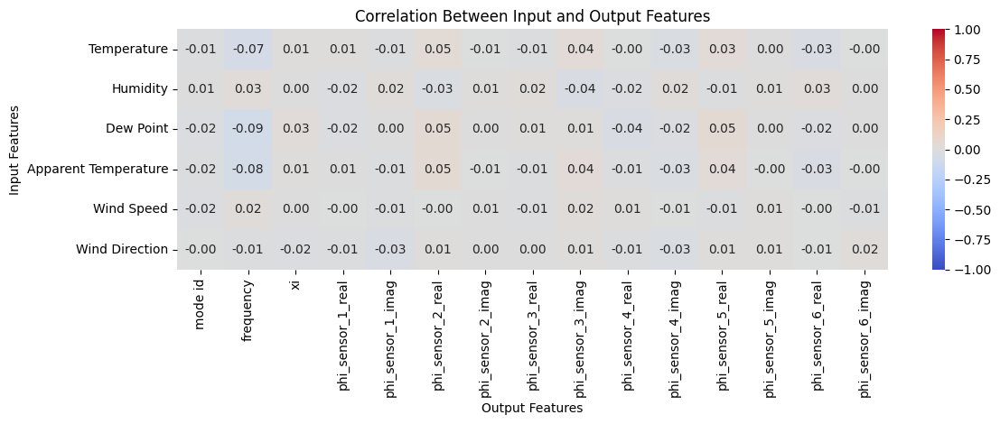

In [10]:
fig = plot_correlation(weather_df, df_modeshapes, mode='input-output')

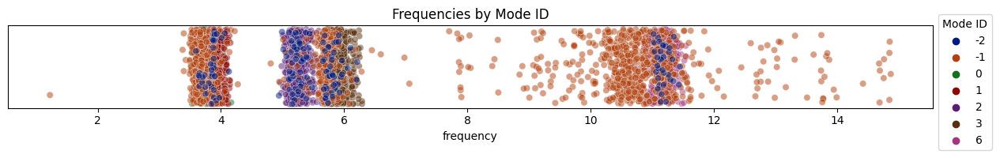

In [11]:
y_jitter = np.random.uniform(-0.1, 0.1, size=len(modeshapes_df))

plt.figure(figsize=(12, 2))
sns.scatterplot(x='frequency', y=y_jitter, hue='mode_id', data=modeshapes_df, palette='dark', alpha=0.5)
plt.yticks([])
plt.xlabel('frequency')
plt.title('Frequencies by Mode ID')
plt.tight_layout()
plt.legend(title='Mode ID', bbox_to_anchor=(1, 1.2))
plt.show()

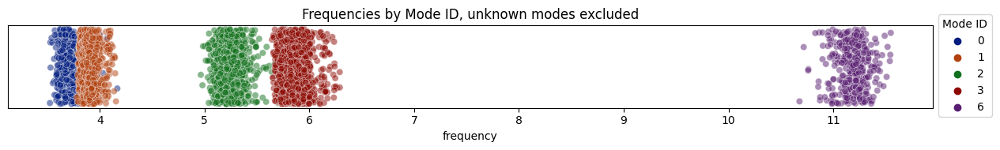

In [12]:
data = modeshapes_df[~modeshapes_df['mode_id'].isin([-1, -2])].copy()

y_jitter = np.random.uniform(-0.1, 0.1, size=len(data))

plt.figure(figsize=(12, 2))
sns.scatterplot(x='frequency', y=y_jitter, hue='mode_id', data=data, palette='dark', alpha=0.5)
plt.yticks([])
plt.xlabel('frequency')
plt.title('Frequencies by Mode ID, unknown modes excluded')
plt.tight_layout()
plt.legend(title='Mode ID', bbox_to_anchor=(1, 1.2))
plt.show()

In [13]:
# Sort the mode_id categories
sorted_modes = sorted(modeshapes_df['mode_id'].unique())
mode_id_mapping = {mode: i for i, mode in enumerate(sorted_modes)}

# Apply mapping and add jitter
modeshapes_df['jitter'] = modeshapes_df['mode_id'].map(mode_id_mapping) + np.random.normal(scale=0.1, size=len(modeshapes_df))

# Create plot
fig = px.scatter(modeshapes_df, x='jitter', y='frequency', width=1500, height=400)
fig.update_traces(marker=dict(color='royalblue'))

# Update layout with title and x-axis labels
fig.update_layout(
    title=dict(
        text='Frequencies by Mode ID with Jitter',
        x=0.5,
        xanchor='center',
        font=dict(size=18)
    ),
    xaxis=dict(
        tickmode='array',
        tickvals=list(mode_id_mapping.values()),
        ticktext=list(mode_id_mapping.keys()),
        title='Mode ID'
    ),
    yaxis=dict(title='Frequency')
)

fig.show()

/home/vemese/miniforge3/envs/Buildchain_sandbox/lib/python3.10/site-packages/plotly/io/_renderers.py:395: DeprecationWarning:

distutils Version classes are deprecated. Use packaging.version instead.



In [14]:
fig = scatter_plot_modes_subplots(modeshapes_dict, x_key='Temperature', y_key='frequency', modes=[0, 1, 2, 3, 6])
fig.show()

In [15]:
fig = scatter_plot_modes_subplots(modeshapes_dict, x_key='Humidity', y_key='frequency', modes=[0, 1, 2, 3, 6])
fig.show()

# Mode 0

In [16]:
mode = 0

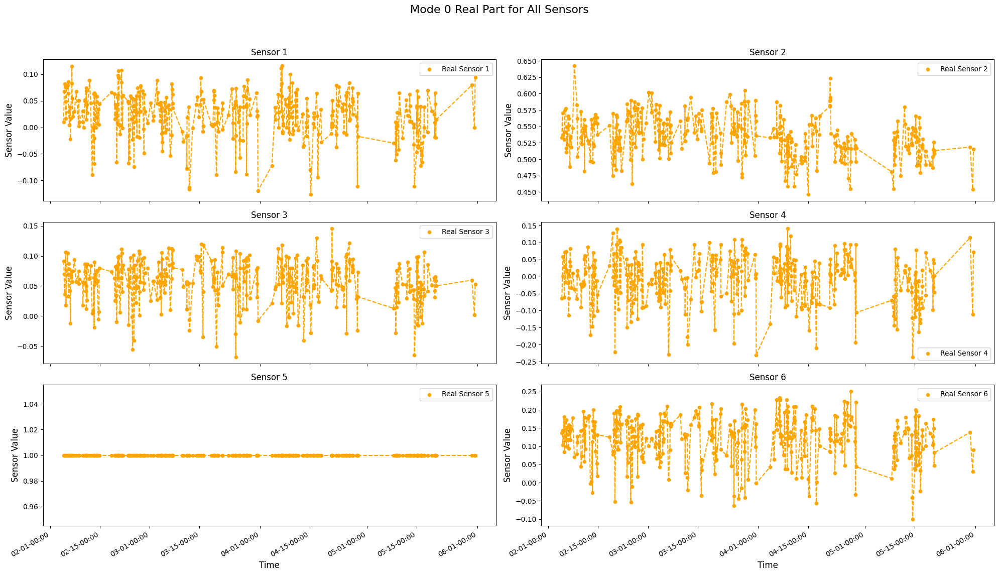

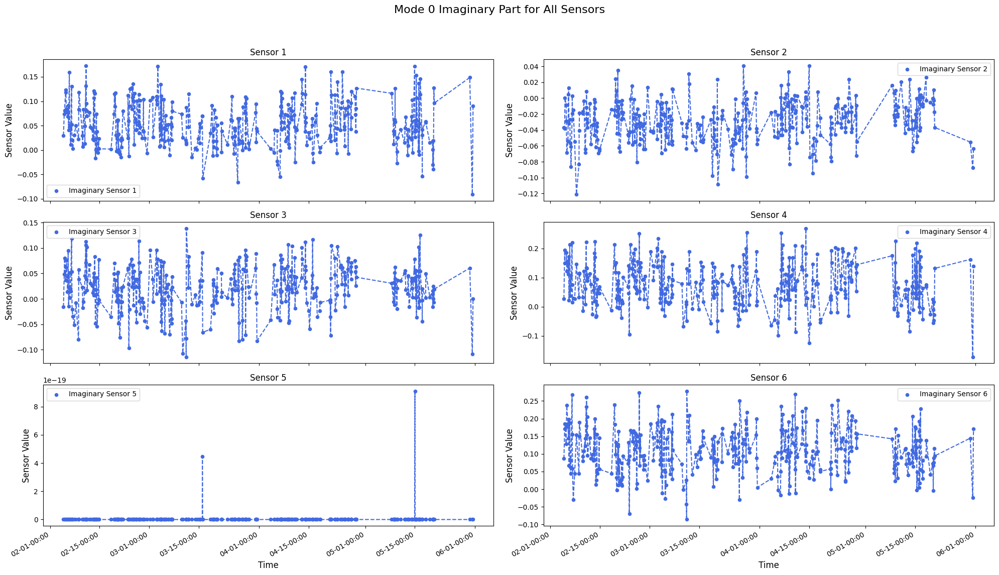

In [17]:
fig_real, fig_imag = plot_parts(mode)

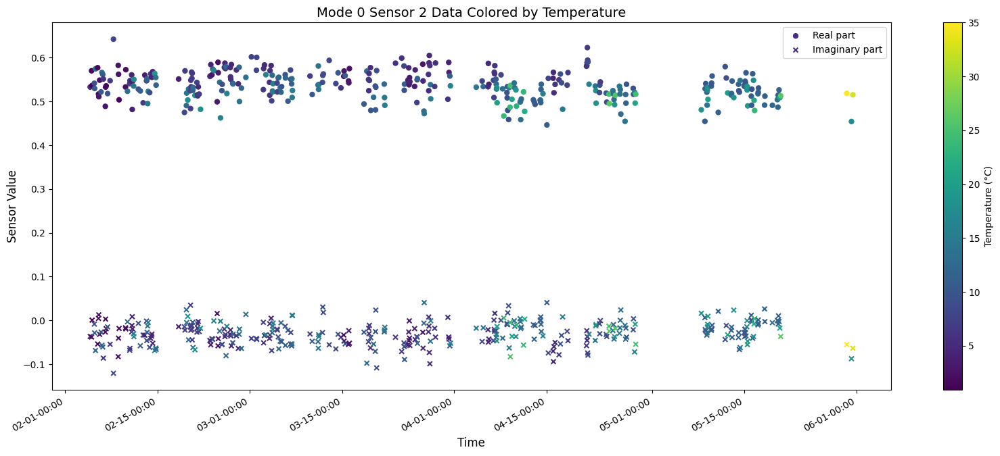

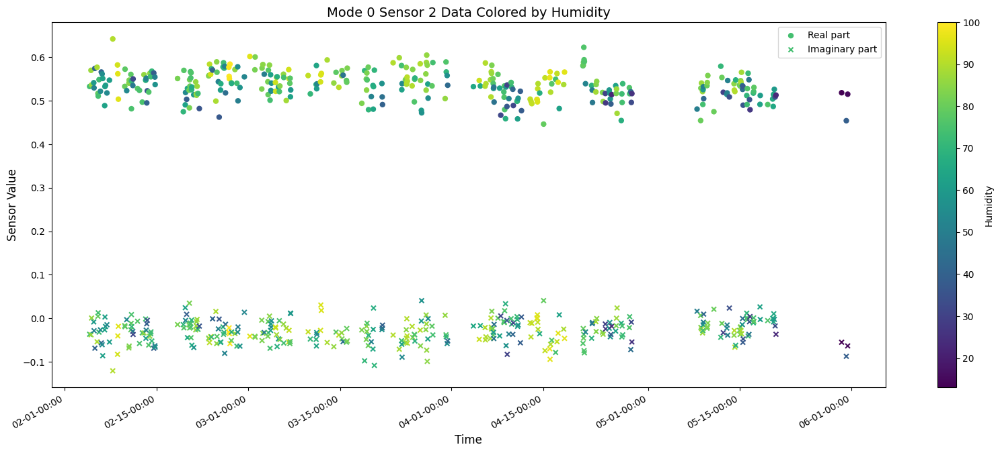

In [18]:
fig_temp = plot_sensor_complex_colored(mode, sensor=2, color_by='Temperature')
fig_hum = plot_sensor_complex_colored(mode, sensor=2, color_by='Humidity')

/home/vemese/miniforge3/envs/Buildchain_sandbox/lib/python3.10/site-packages/IPython/core/events.py:89: UserWarning:

Attempting to set identical low and high xlims makes transformation singular; automatically expanding.

/home/vemese/miniforge3/envs/Buildchain_sandbox/lib/python3.10/site-packages/IPython/core/pylabtools.py:152: UserWarning:

Attempting to set identical low and high xlims makes transformation singular; automatically expanding.



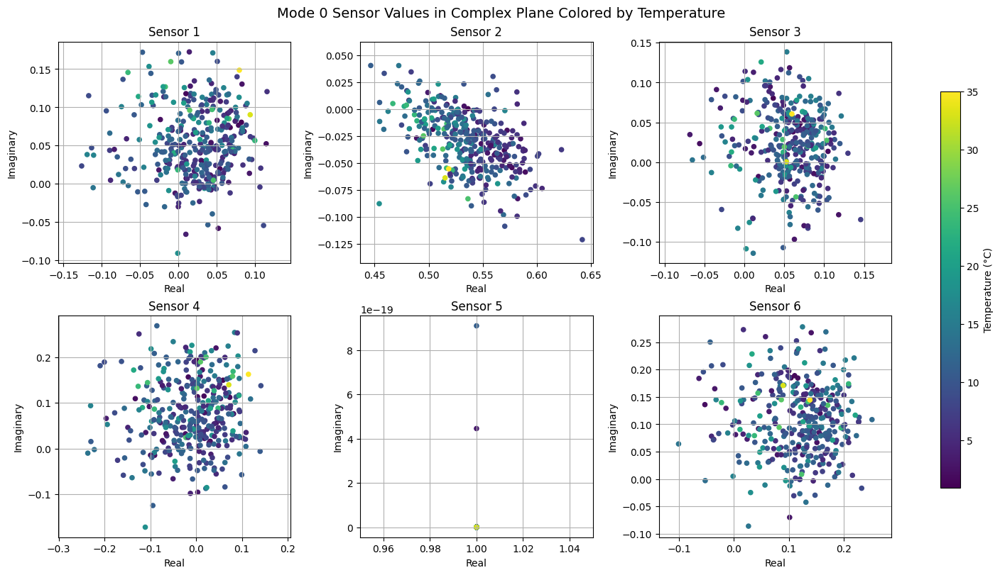

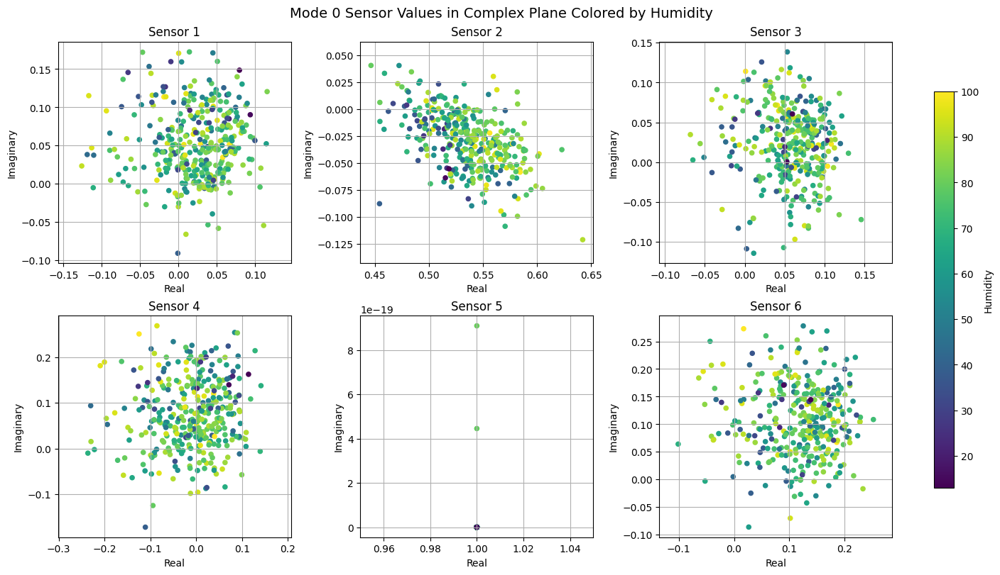

In [19]:
fig_temp = plot_complex_plane_all_sensors(mode, color_by='Temperature')
fig_hum = plot_complex_plane_all_sensors(mode, color_by='Humidity')

In [20]:
fig = plot_mode_shapes_3d(mode, color_by='Temperature')
fig.show()

In [21]:
fig = plot_mode_shapes_3d(mode, color_by='Humidity')
fig.show()

# Mode 1

In [22]:
mode = 1

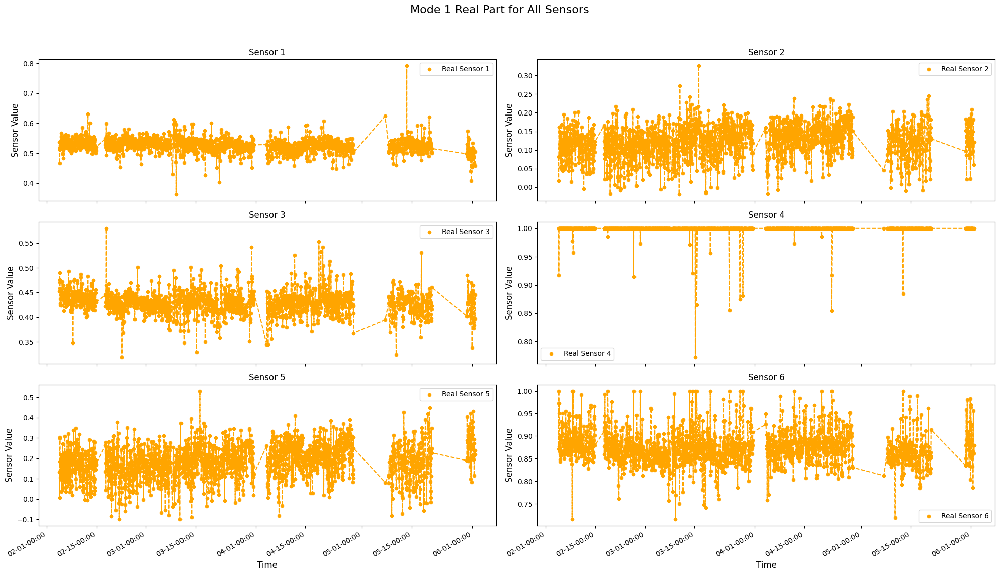

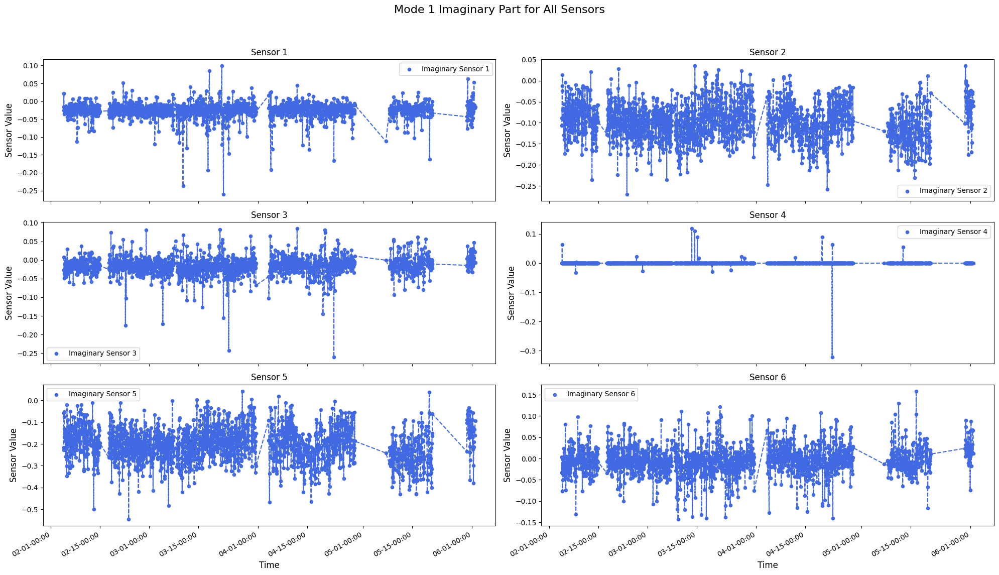

In [23]:
fig_real, fig_imag = plot_parts(mode)

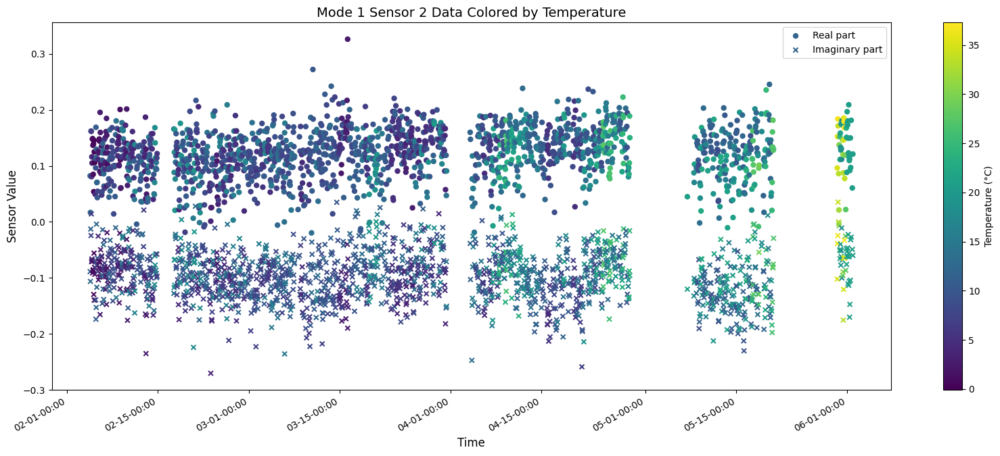

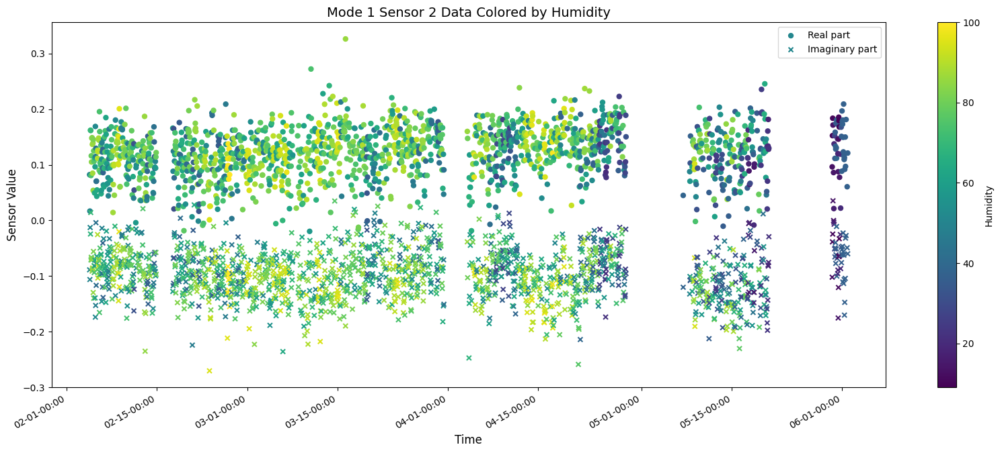

In [24]:
fig_temp = plot_sensor_complex_colored(mode, sensor=2, color_by='Temperature')
fig_hum = plot_sensor_complex_colored(mode, sensor=2, color_by='Humidity')

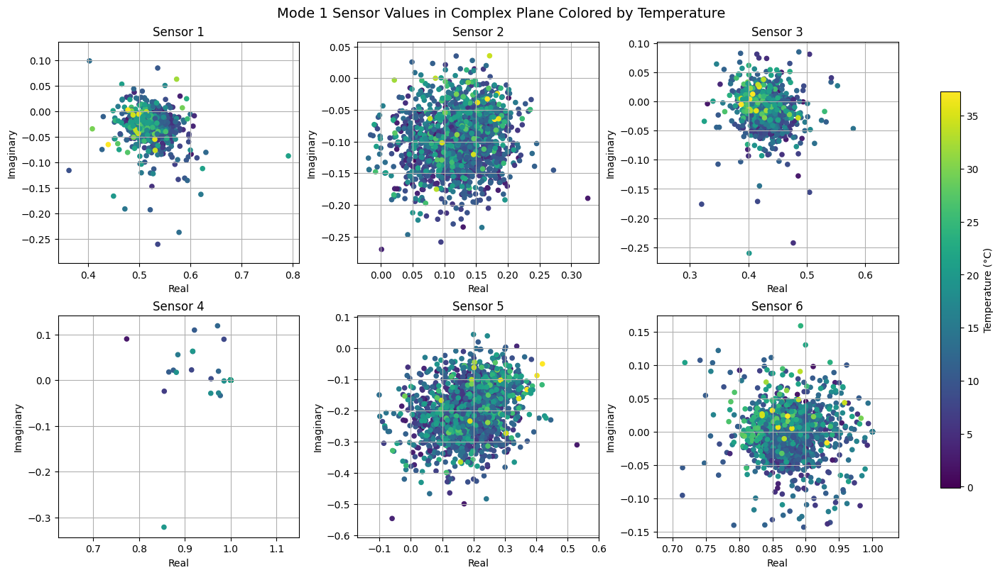

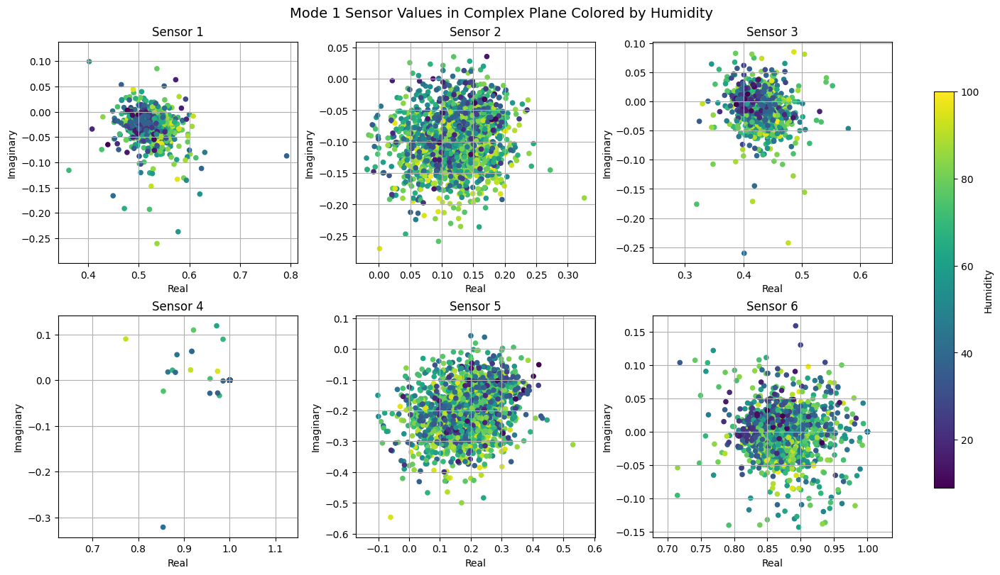

In [25]:
fig_temp = plot_complex_plane_all_sensors(mode, color_by='Temperature')
fig_hum = plot_complex_plane_all_sensors(mode, color_by='Humidity')

In [26]:
fig = plot_mode_shapes_3d(mode, color_by='Temperature')
fig.show()

In [27]:
fig = plot_mode_shapes_3d(mode, color_by='Humidity')
fig.show()

# Mode 2

In [28]:
mode = 2

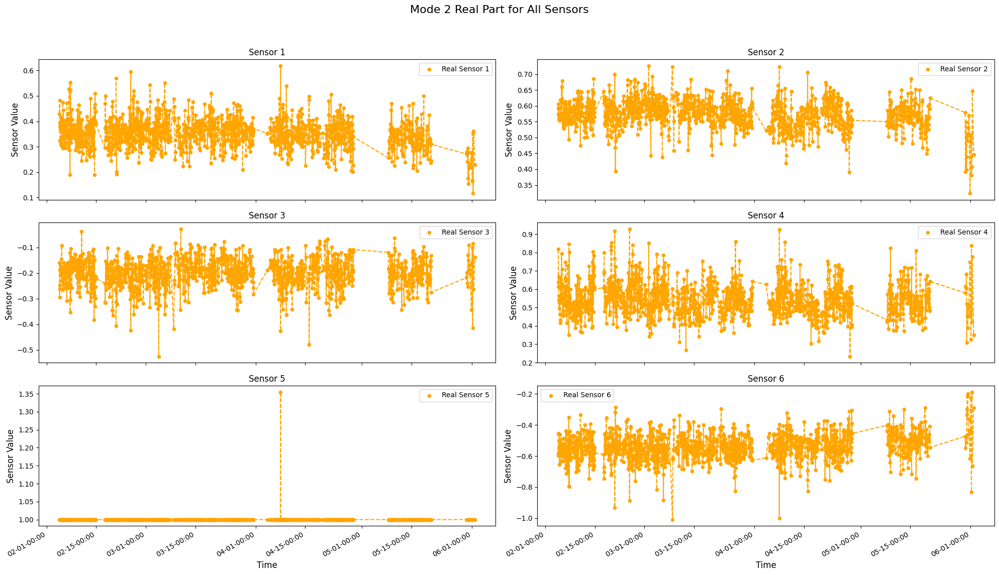

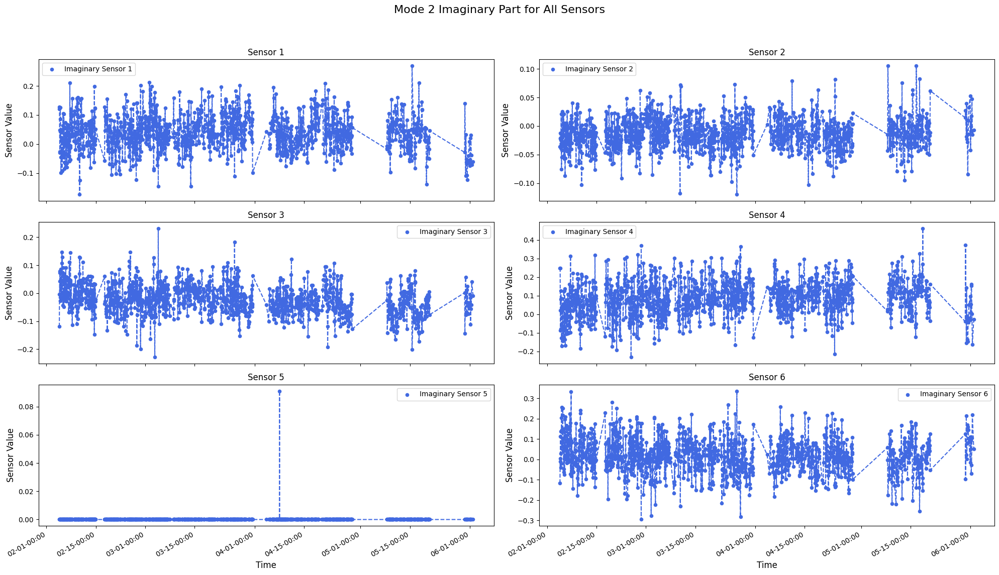

In [29]:
fig_real, fig_imag = plot_parts(mode)

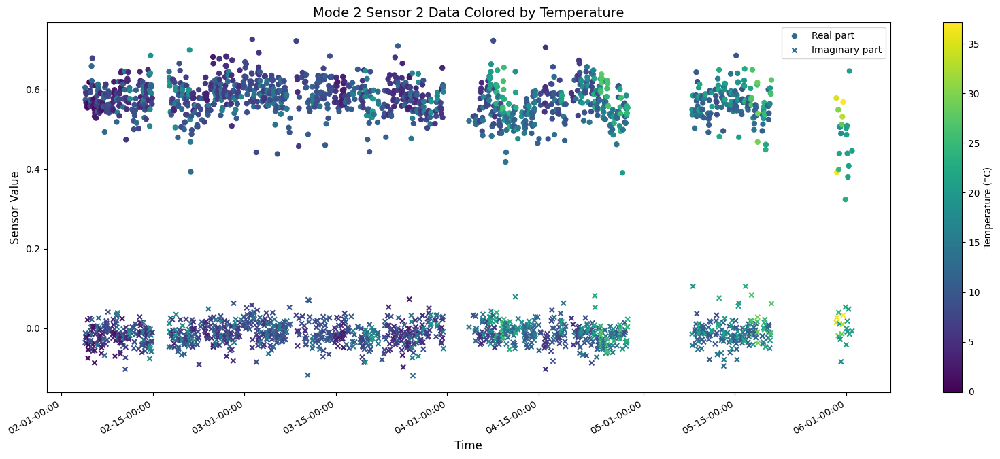

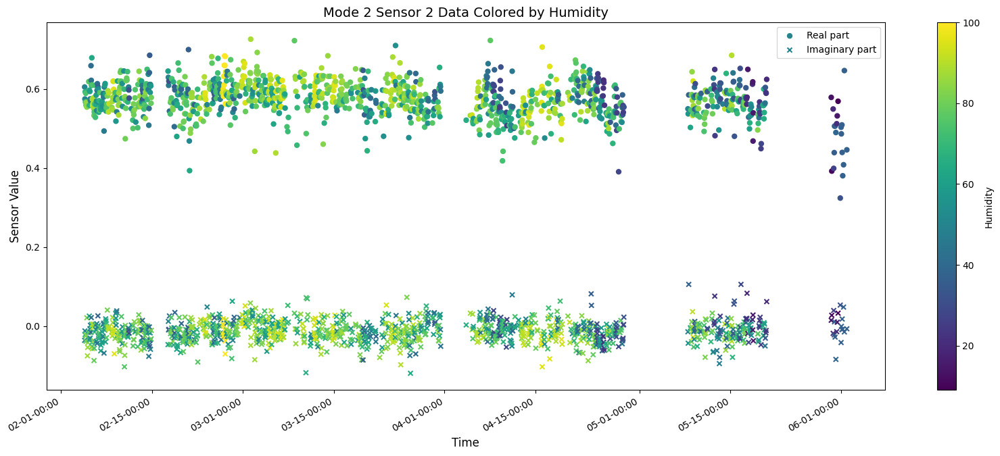

In [30]:
fig_temp = plot_sensor_complex_colored(mode, sensor=2, color_by='Temperature')
fig_hum = plot_sensor_complex_colored(mode, sensor=2, color_by='Humidity')

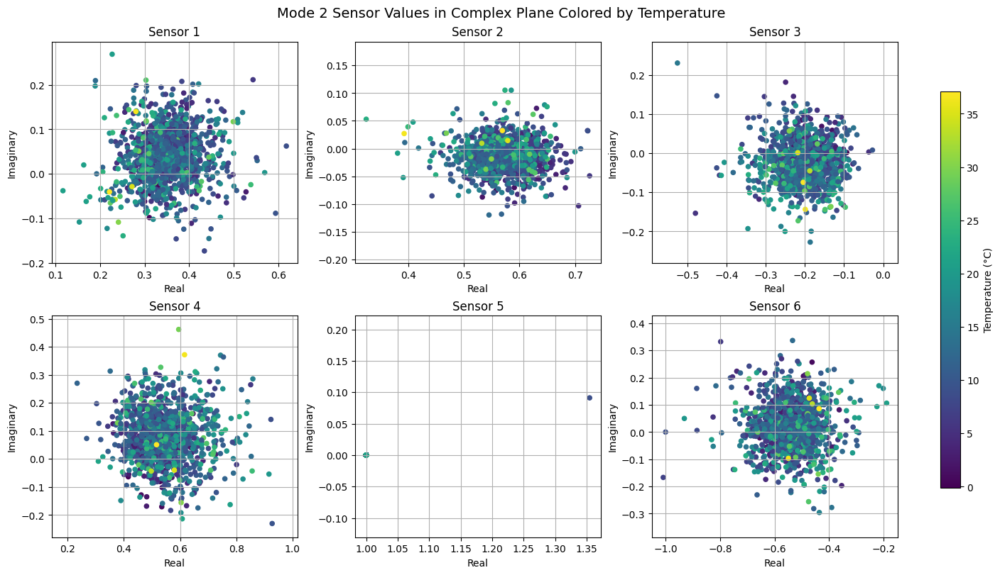

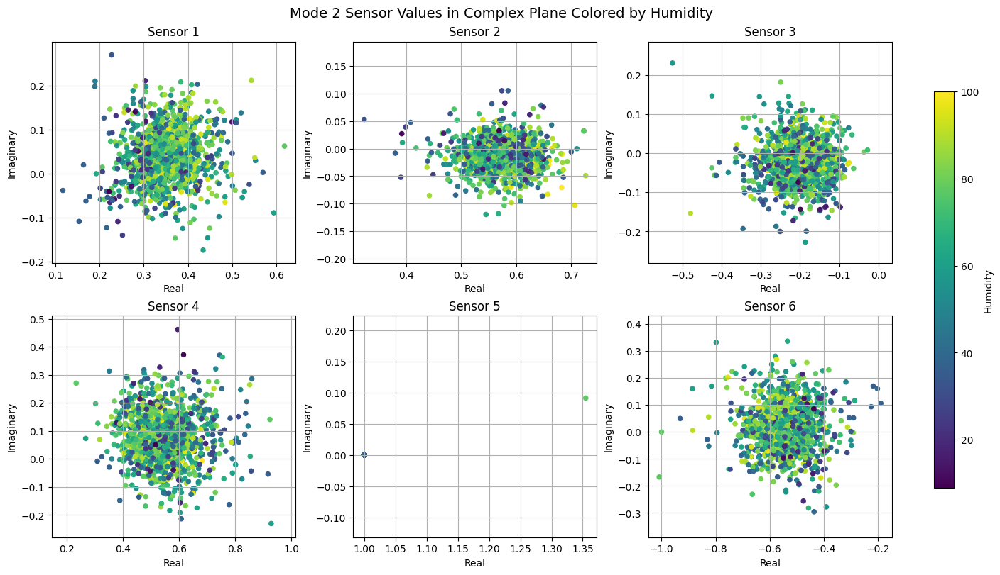

In [31]:
fig_temp = plot_complex_plane_all_sensors(mode, color_by='Temperature')
fig_hum = plot_complex_plane_all_sensors(mode, color_by='Humidity')

In [32]:
fig = plot_mode_shapes_3d(mode, color_by='Temperature')
fig.show()

In [33]:
fig = plot_mode_shapes_3d(mode, color_by='Humidity')
fig.show()

# Mode 3

In [34]:
mode = 3

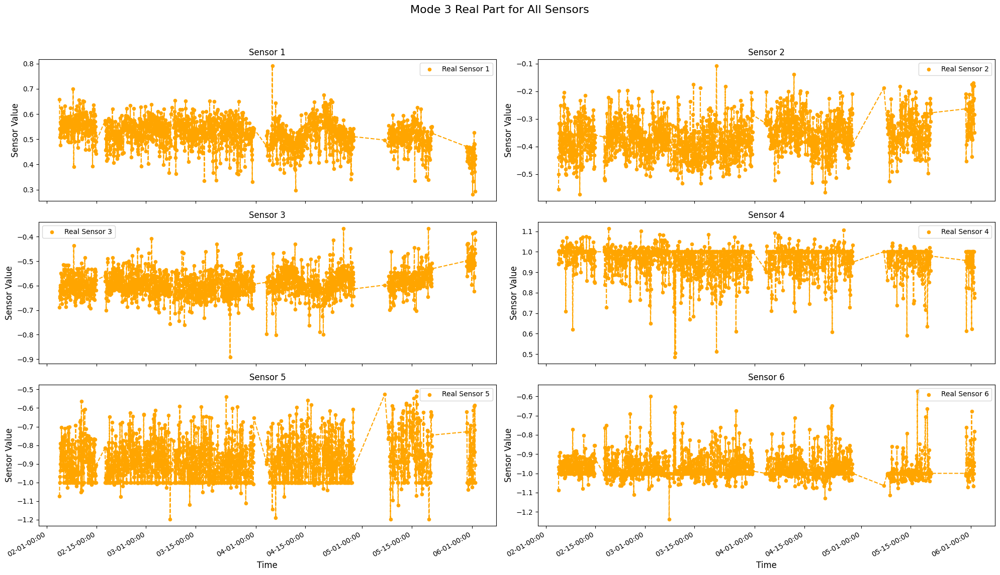

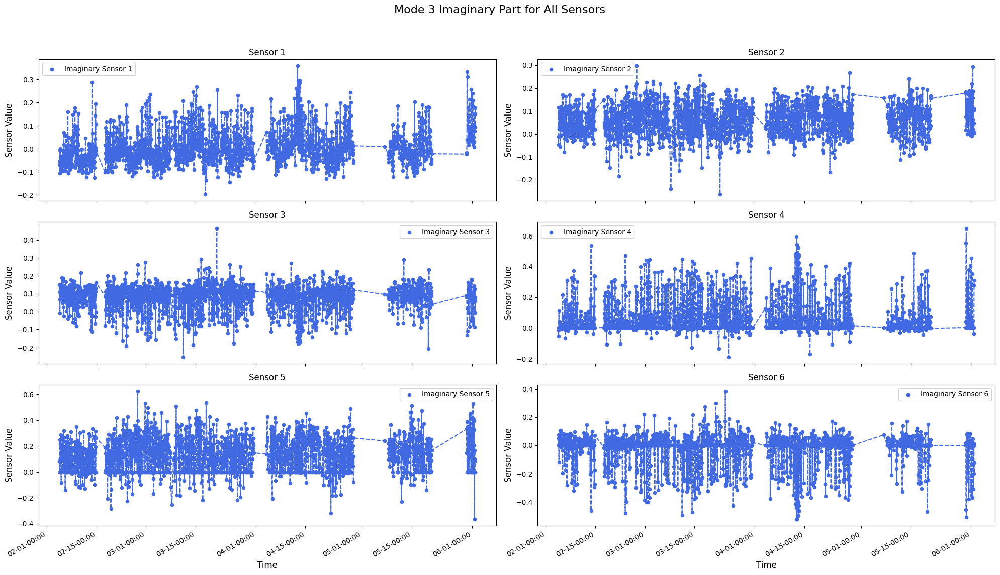

In [35]:
fig_real, fig_imag = plot_parts(mode)

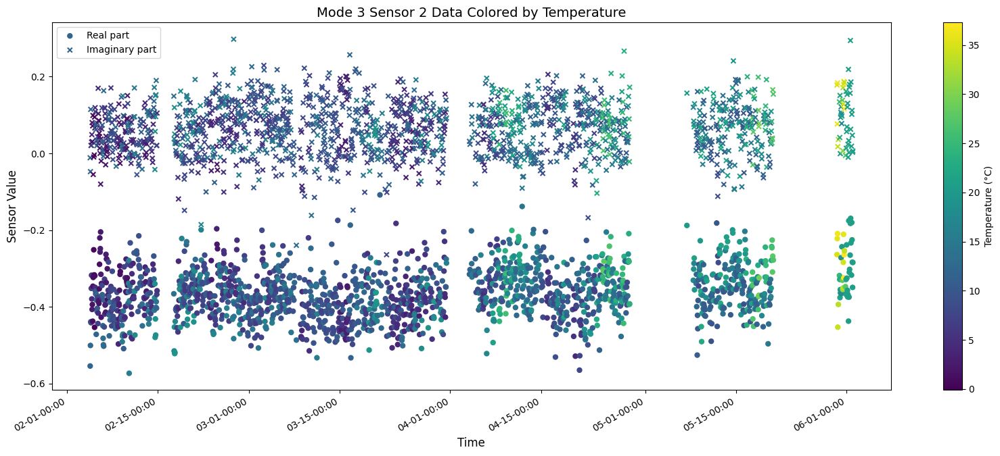

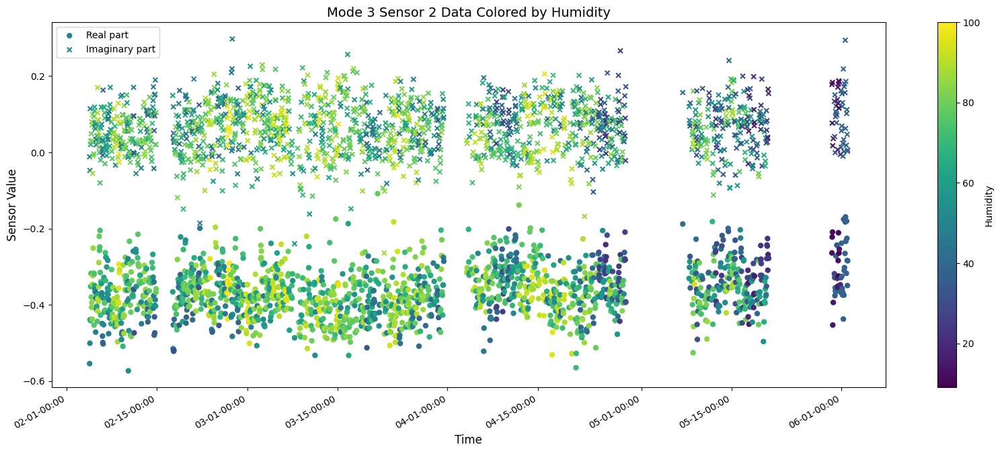

In [36]:
fig_temp = plot_sensor_complex_colored(mode, sensor=2, color_by='Temperature')
fig_hum = plot_sensor_complex_colored(mode, sensor=2, color_by='Humidity')

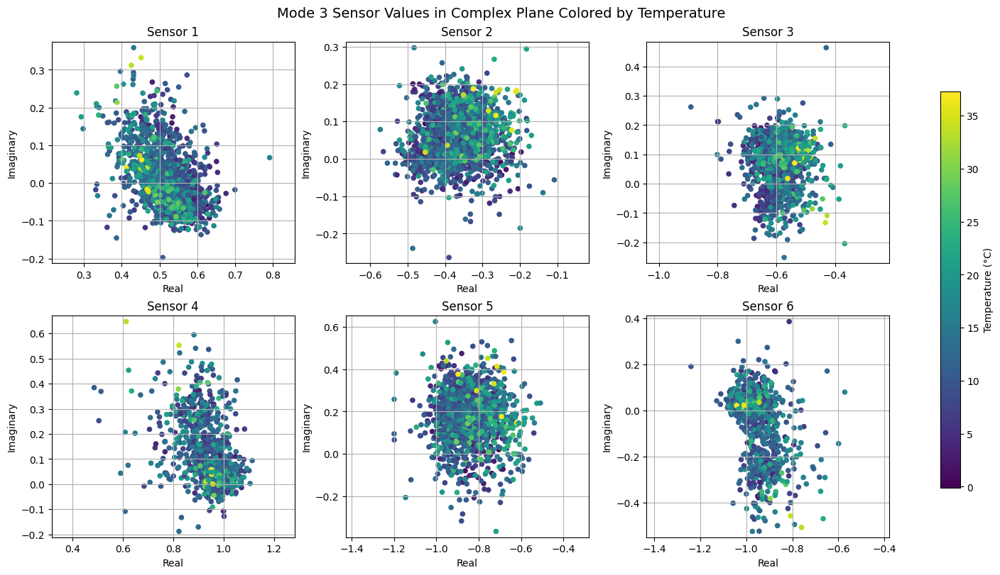

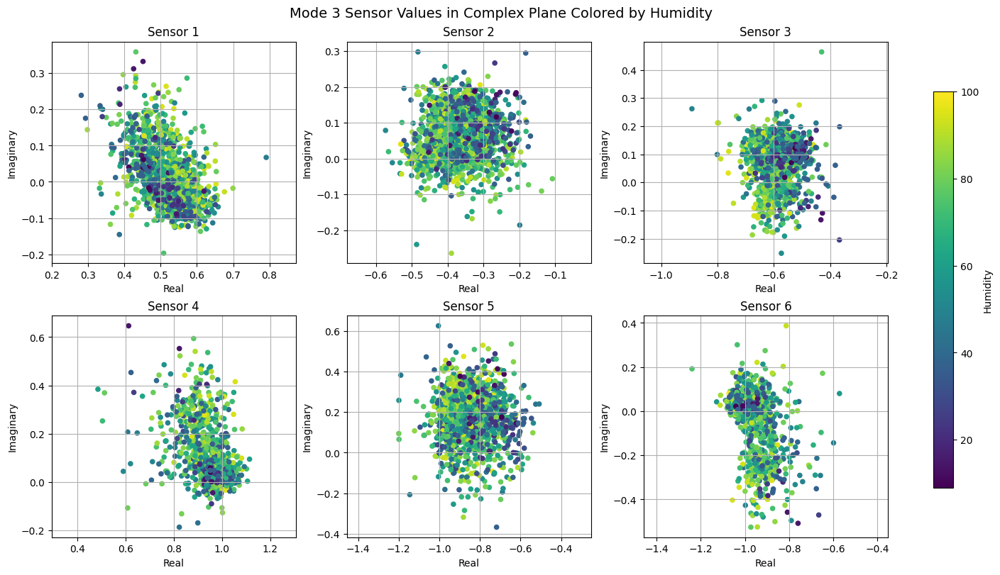

In [37]:
fig_temp = plot_complex_plane_all_sensors(mode, color_by='Temperature')
fig_hum = plot_complex_plane_all_sensors(mode, color_by='Humidity')

In [38]:
fig = plot_mode_shapes_3d(mode, color_by='Temperature')
fig.show()

In [39]:
fig = plot_mode_shapes_3d(mode, color_by='Humidity')
fig.show()

# Mode 6

In [40]:
mode = 6

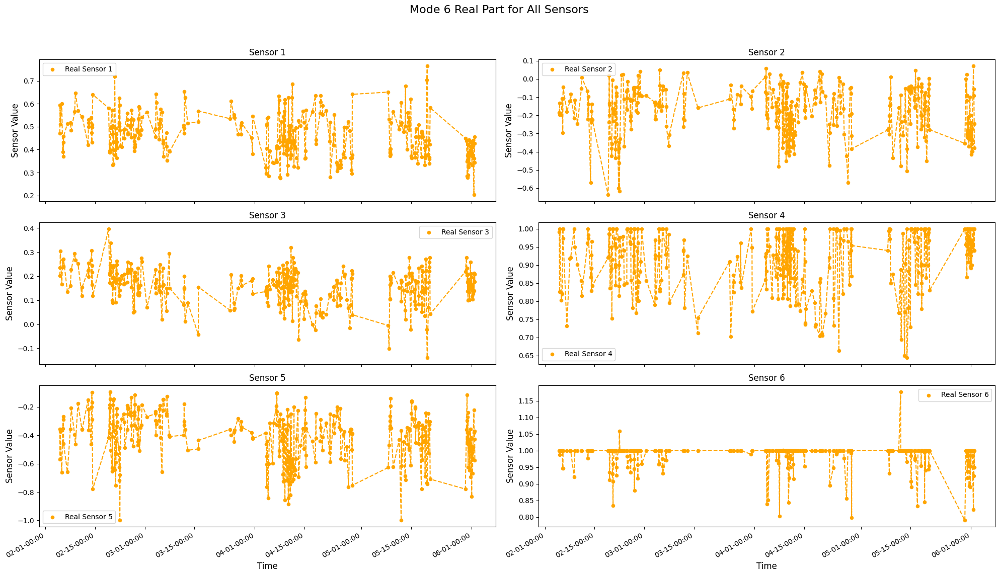

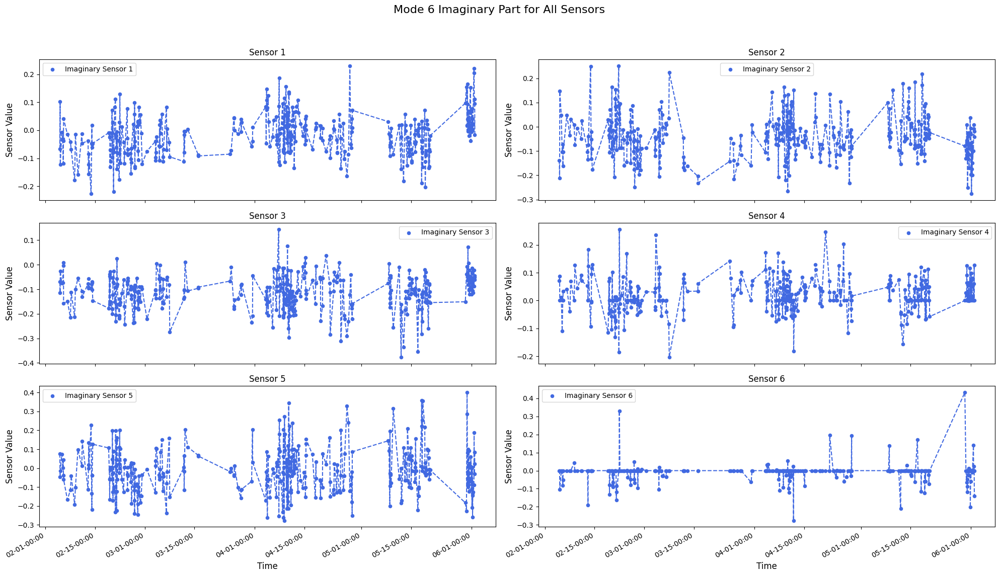

In [41]:
fig_real, fig_imag = plot_parts(mode)

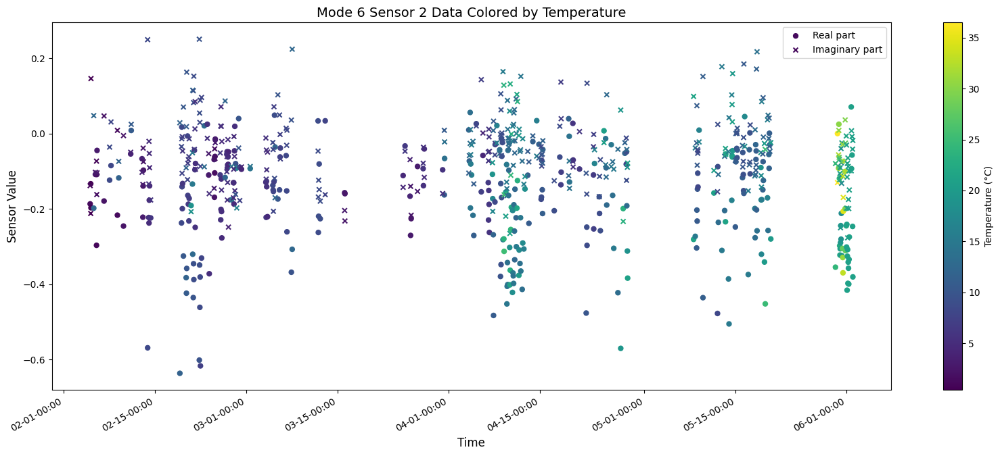

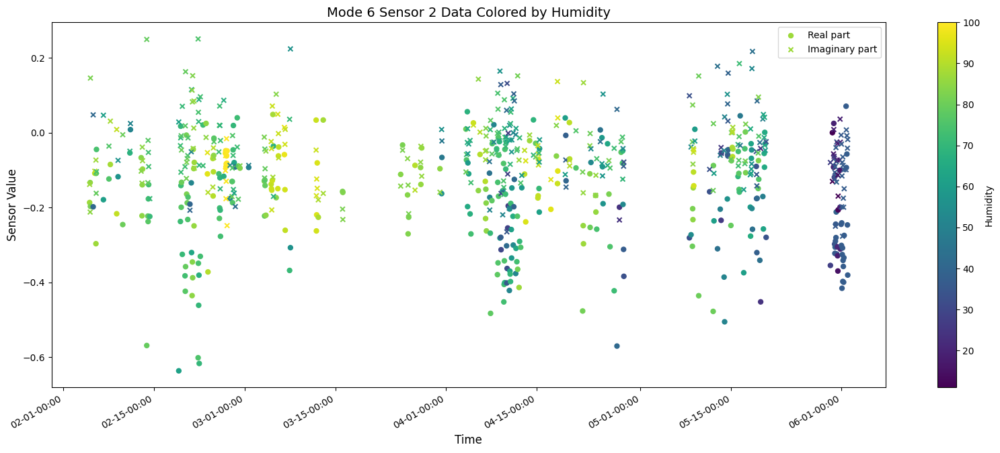

In [42]:
fig_temp = plot_sensor_complex_colored(mode, sensor=2, color_by='Temperature')
fig_hum = plot_sensor_complex_colored(mode, sensor=2, color_by='Humidity')

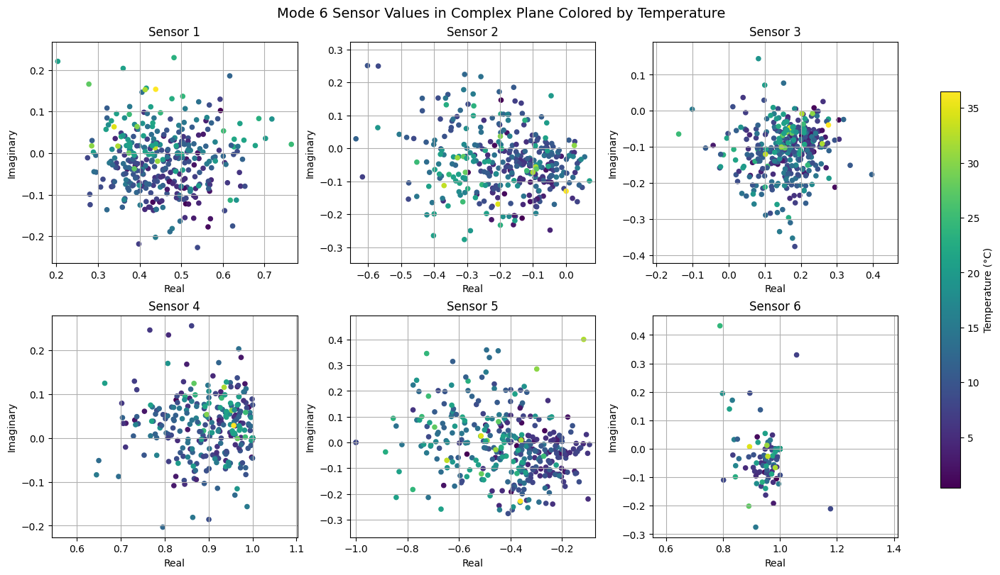

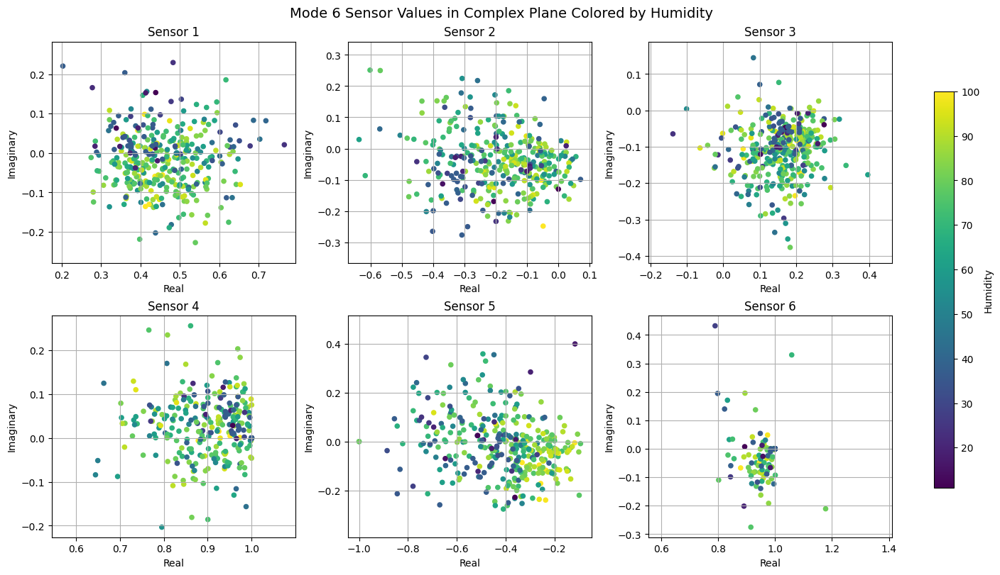

In [43]:
fig_temp = plot_complex_plane_all_sensors(mode, color_by='Temperature')
fig_hum = plot_complex_plane_all_sensors(mode, color_by='Humidity')

In [44]:
fig = plot_mode_shapes_3d(mode, color_by='Temperature')
fig.show()

In [45]:
fig = plot_mode_shapes_3d(mode, color_by='Humidity')
fig.show()